In [ ]:
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

In [ ]:
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood
from pyCRLD.Utils import FlowPlot as fp

import numpy as np
import itertools as it
import matplotlib.pyplot as plt
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from datetime import datetime

In [ ]:
from DistBase import distbase

## Medium collapse impact

In [ ]:
# Define environment
env = EcologicalPublicGood(N=2, f=1.2, c=5, m=-4, qc=0.2, qr=0.1, degraded_choice=True)
env

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


EcologicalPublicGood_2_1.2_5_-4_0.2_0.1_DegChoi

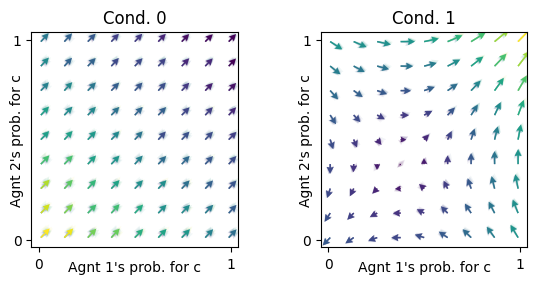

In [ ]:
# Init enviornment and MultiAgentEnvironment-interface
mae = stratAC(env=env, learning_rates=0.1, discount_factors=0.9, use_prefactor=True)

x = ([0], [0,1], [0])  # Plotting only the prosperous state
y = ([1], [0,1], [0])  # Plotting only the prosperous state
ax = fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16)

In [ ]:
db = distbase(env, nr_reward_bins=60, discretization_sigma=0.1, learning_rates=0.1, discount_factors=0.9)

KeyboardInterrupt: 

In [ ]:
x = ([0], [0,1], [0])  # Plotting only the prosperous state
y = ([1], [0,1], [0])  # Plotting only the prosperous state
ax = fp.plot_strategy_flow(db, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16)

In [ ]:
# X_init = jnp.zeros((2, 2, 2))
X_init = X_init.at[:, :, 0].set(jnp.array([[.3, .3], [.3, .3]]))
X_init = X_init.at[:, :, 1].set(jnp.array([[.7, .7], [.7, .7]]))

In [ ]:
@partial(jit, static_argnums=0)
def compute_trajectory(steps):
    Xisat = jnp.zeros((2, 2, 2, steps))
    Xisa = X_init
    # Xisa = jnp.array(mae.random_softmax_strategy())
    for t in range(steps):
        Xisat = Xisat.at[:, :, :, t].set(Xisa)
        Risar = db.Risar(Xisa)
        Risa = jnp.einsum('ijkl,l->ijk', Risar, db.gridpoints)
        Visv = db.Visv(Xisa)
        Visav = jnp.zeros((2, 2, 2, db.nr))
        Visav = Visav.at[:, :, 0, :].set(Visv)
        Visav = Visav.at[:, :, 1, :].set(Visv)
        Visa = jnp.einsum('ijkl,l->ijk', Visav, db.gridpoints)
        nextVisa = jnp.einsum('ijkl,l->ijk', db.nextVisav(Xisa), db.gridpoints)
        n = jnp.newaxis 
        Disa = (1 - db.gamma[:,n,n]) * Risa + db.gamma[:,n,n] * nextVisa - Visa
        XexpaTDe = Xisa * jnp.exp(db.alpha[:,n,n] * Disa)
        Xisa = XexpaTDe / XexpaTDe.sum(-1, keepdims=True)
    return Xisat

In [ ]:
Xisat = compute_trajectory(10)

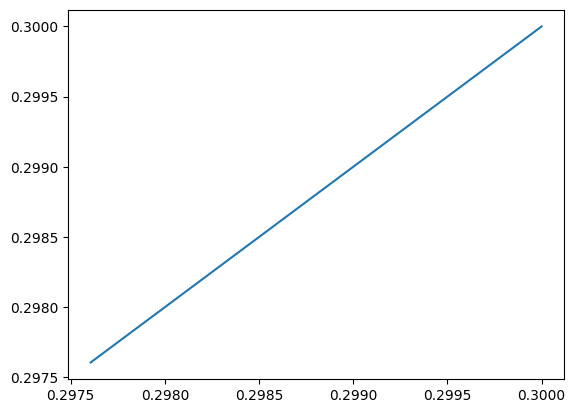

In [ ]:
plt.figure()
plt.plot(Xisat[0,1,0], Xisat[1,1,0])
plt.show()